[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nlavadodatasci/atd-megaf-fiabilidade/blob/main/00_comum/testes_de_ajustamento.ipynb)

# Testes de ajustamento em Python

**ATD — MEGAF 2026/27 · Atividade de Fiabilidade · material comum a todos os grupos**

Na aula testámos, em Excel, se os tempos até à falha de um componente seguiam uma distribuição exponencial. Este *notebook* repete esse teste em Python, com os mesmos dados, e depois vai um pouco mais longe.

1. Ler os dados da aula
2. Olhar para os dados antes de testar
3. O teste do qui-quadrado, passo a passo, tal como no Excel
4. O mesmo teste com classes de igual probabilidade (mais robusto)
5. Outros testes: Kolmogorov–Smirnov e gráfico quantil–quantil
6. Comparar as quatro distribuições do documento base
7. O que muda quando há poucos dados
8. A sua vez

**Como usar:** execute as células por ordem (Shift+Enter). Leia o texto antes de cada célula e compare os resultados com os do Excel da aula.

## 1. Ler os dados da aula

In [1]:
import os, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

FICHEIRO = "tempo_falhas_aula.xlsx"
URL = "https://raw.githubusercontent.com/nlavadodatasci/atd-megaf-fiabilidade/main/dados/" + FICHEIRO

# Se o ficheiro ainda não estiver no Colab, vai buscá-lo ao repositório.
# Se isso falhar, abre uma janela para o escolher no seu computador
if not os.path.exists(FICHEIRO):
    try:
        urllib.request.urlretrieve(URL, FICHEIRO)
    except Exception:
        from google.colab import files
        print("Escolha no seu computador o ficheiro", FICHEIRO)
        carregados = files.upload()
        if FICHEIRO not in carregados:               # veio com outro nome: renomeia
            os.rename(list(carregados)[0], FICHEIRO)

aula = pd.read_excel(FICHEIRO, sheet_name="tempo_falhas", usecols="A:B")
t = aula.iloc[:, 1].dropna().to_numpy()      # segunda coluna: tempos até à falha (horas)
n = len(t)
print("Número de tempos:", n)
print("Primeiros valores:", t[:5])

Número de tempos: 9998
Primeiros valores: [1.  1.2 2.  2.1 3. ]


O MTBF e a taxa de falha calculam-se como no Excel (`=AVERAGE(...)` e `=1/MTBF`). Confirme que os valores são os mesmos da folha `tempo_falhas`.

In [2]:
mtbf = t.mean()
lam = 1 / mtbf
print(f"MTBF   = {mtbf:.2f} horas")
print(f"lambda = {lam:.8f} falhas por hora")

MTBF   = 8738.14 horas
lambda = 0.00011444 falhas por hora


## 2. Olhar para os dados antes de testar

Antes de qualquer teste, sobreponha o histograma dos dados à curva do modelo. Se não se parecem, o modelo não serve.

Em `scipy.stats`, uma distribuição exponencial com média igual ao MTBF cria-se com `stats.expon(scale=mtbf)`. A partir daí:

- `modelo.pdf(x)` é a densidade $f(x)$
- `modelo.cdf(x)` é a função de distribuição acumulada $F(x)$
- `modelo.sf(x)` é a fiabilidade $R(x) = 1 - F(x)$

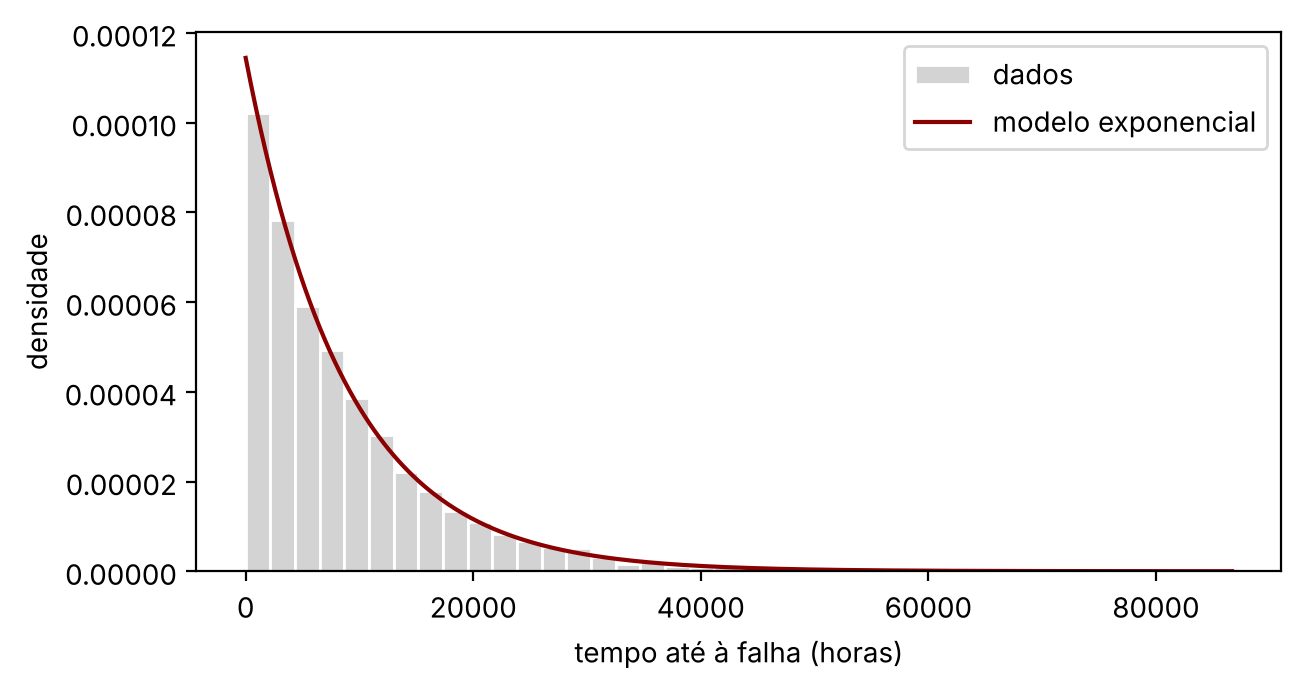

In [3]:
modelo = stats.expon(scale=mtbf)

x = np.linspace(0, t.max(), 400)
plt.figure(figsize=(7, 3.5))
plt.hist(t, bins=40, density=True, color="lightgray", edgecolor="white", label="dados")
plt.plot(x, modelo.pdf(x), color="darkred", label="modelo exponencial")
plt.xlabel("tempo até à falha (horas)"); plt.ylabel("densidade"); plt.legend()
plt.show()

## 3. O teste do qui-quadrado, passo a passo (como no Excel)

O teste compara, classe a classe, o número de falhas **observado** com o número **esperado** pelo modelo.

### Passo 1 — Construir as classes

No Excel usámos a regra de Sturges para o número de classes e dividimos o intervalo entre o mínimo e o máximo em classes de igual amplitude. As quatro últimas, com poucas falhas, foram juntas numa só. Acrescentámos ainda uma classe abaixo do mínimo e outra acima do máximo, para as probabilidades somarem 1.

In [4]:
k_sturges = int(1 + np.log2(n))                 # no Excel: =TRUNC(1+LOG(n,2))
amplitude = (t.max() - t.min()) / k_sturges
print("Classes (Sturges):", k_sturges, "  amplitude:", round(amplitude, 2))

# Limites das classes usadas no teste do Excel:
# 0 | mínimo | 10 classes de igual amplitude | máximo | infinito
limites = np.concatenate([[0],
                          t.min() + amplitude * np.arange(0, 11),
                          [t.max() + 0.001],     # +0.001 para o valor máximo ficar dentro da classe
                          [np.inf]])
print("Número de classes do teste:", len(limites) - 1)

Classes (Sturges): 14   amplitude: 6192.06
Número de classes do teste: 13


### Passo 2 — Frequências observadas e esperadas

- **Observada**: quantos tempos caem em cada classe (`np.histogram` faz a contagem que no Excel fizemos com `COUNTIF`).
- **Probabilidade da classe**: $F(\text{limite superior}) - F(\text{limite inferior})$. `np.diff` calcula essas diferenças de uma vez.
- **Esperada**: $n \times$ probabilidade.

In [5]:
obs = np.histogram(t, bins=limites)[0]          # frequências observadas
p = np.diff(modelo.cdf(limites))                # probabilidade de cada classe
esp = n * p                                     # frequências esperadas

tabela = pd.DataFrame({"lim_inf": limites[:-1], "lim_sup": limites[1:],
                       "observada": obs, "p_k": p, "esperada": esp,
                       "(obs-esp)^2/esp": (obs - esp) ** 2 / esp})
print("Soma das probabilidades:", p.sum())
tabela.round(4)

Soma das probabilidades: 1.0


,lim_inf,lim_sup,observada,p_k,esperada,(obs-esp)^2/esp
0,0.0000,1.0000,0,0.0001,1.1441,1.1441
1,1.0000,6193.0571,5046,0.5076,5075.1939,0.1679
2,6193.0571,12385.1143,2533,0.2499,2498.6245,0.4729
3,12385.1143,18577.1714,1229,0.1230,1230.1253,0.0010
4,18577.1714,24769.2286,599,0.0606,605.6165,0.0723
5,24769.2286,30961.2857,322,0.0298,298.1577,1.9066
6,30961.2857,37153.3429,137,0.0147,146.7893,0.6528
7,37153.3429,43345.4000,65,0.0072,72.2675,0.7308
8,43345.4000,49537.4571,33,0.0036,35.5788,0.1869
9,49537.4571,55729.5143,13,0.0018,17.5162,1.1644


Compare esta tabela com as colunas F a L da folha `teste_ajustamento`. Devem ser iguais.

### Passo 3 — Estatística de teste e decisão

A estatística de teste (ET) é a soma da última coluna. Se o modelo for adequado, segue uma distribuição do qui-quadrado com

$$\text{gl} = k - 1 - m$$

graus de liberdade, em que $k$ é o número de classes e $m$ o número de parâmetros estimados a partir dos dados. Na exponencial estimámos um parâmetro ($\lambda$), logo $m = 1$.

O **valor-p** é a probabilidade de obter uma ET tão grande ou maior, se o modelo estiver certo. Regra de decisão: se o valor-p for inferior a 0,05, rejeita-se o modelo.

In [6]:
ET = ((obs - esp) ** 2 / esp).sum()
k = len(obs)
m = 1                                           # parâmetros estimados (lambda)
gl = k - 1 - m
valor_p = stats.chi2.sf(ET, gl)                 # no Excel: =CHISQ.DIST.RT(ET, gl)

print(f"ET = {ET:.4f}")
print(f"gl = {k} - 1 - {m} = {gl}")
print(f"valor-p = {valor_p:.4f}")
print("Conclusão:", "rejeita-se o modelo" if valor_p < 0.05 else "não se rejeita o modelo exponencial")

ET = 8.2216
gl = 13 - 1 - 1 = 11
valor-p = 0.6933
Conclusão: não se rejeita o modelo exponencial


A ET é a mesma do Excel (8,22). Na folha da aula o valor-p foi calculado com 12 graus de liberdade; descontando o parâmetro estimado ficam 11. A conclusão é a mesma nos dois casos.

### O mesmo numa linha

A função `stats.chisquare` faz os passos 2 e 3. O argumento `ddof` é o número de parâmetros estimados.

In [7]:
stats.chisquare(obs, esp, ddof=1)

Power_divergenceResult(statistic=np.float64(8.221624167416044), pvalue=np.float64(0.6933242516581083))

### Um cuidado: classes com poucas falhas esperadas

Repare na coluna `esperada` da tabela: a primeira e a última classe têm valores muito pequenos. O teste do qui-quadrado funciona mal nessas condições. A regra habitual é exigir **pelo menos 5 falhas esperadas por classe**, juntando classes vizinhas quando for preciso.

A secção seguinte mostra uma forma de construir as classes que evita este problema à partida.

### Tudo numa função

O Python não traz uma função que receba os tempos, faça as classes sozinha e aplique o teste: `stats.chisquare` precisa das frequências já calculadas. A função seguinte faz os três passos de uma vez, para qualquer distribuição:

- cria classes de igual amplitude, em número dado pela regra de Sturges;
- junta as classes vizinhas com menos de 5 falhas esperadas;
- devolve a estatística de teste, os graus de liberdade e o valor-p.

O argumento `m` é o número de parâmetros estimados a partir dos dados (1 na exponencial, 2 nas outras três distribuições).

In [8]:
def qui2_automatico(tempos, modelo, m, k=None, minimo=5):
    n = len(tempos)
    if k is None:
        k = int(1 + np.log2(n))                       # regra de Sturges
    limites = np.linspace(tempos.min(), tempos.max(), k + 1)
    limites[0], limites[-1] = modelo.ppf(0), np.inf   # classes dos extremos abertas
    obs = list(np.histogram(tempos, bins=limites)[0])
    esp = list(n * np.diff(modelo.cdf(limites)))
    i = 0
    while i < len(esp) and len(esp) > 1:              # junta classes com esperada < minimo
        if esp[i] < minimo:
            j = i + 1 if i + 1 < len(esp) else i - 1  # classe vizinha
            esp[j] = esp[j] + esp[i]
            obs[j] = obs[j] + obs[i]
            del esp[i], obs[i]
            i = min(i, j)
        else:
            i += 1
    obs, esp = np.array(obs), np.array(esp)
    ET = ((obs - esp) ** 2 / esp).sum()
    gl = len(obs) - 1 - m
    return ET, gl, stats.chi2.sf(ET, gl)

ET, gl, valor_p = qui2_automatico(t, modelo, m=1)
print(f"ET = {ET:.2f}   gl = {gl}   valor-p = {valor_p:.4f}")

ET = 6.34   gl = 9   valor-p = 0.7050


Os números não coincidem com os do Excel, porque a função juntou as classes dos extremos. A conclusão é a mesma: não se rejeita a exponencial.

## 4. Classes de igual probabilidade

Em vez de classes com a mesma amplitude, escolhem-se classes com a mesma **probabilidade** segundo o modelo. Com $k$ classes, cada uma tem probabilidade $1/k$ e frequência esperada $n/k$. Nenhuma fica com poucas falhas esperadas.

Os limites dessas classes são os quantis do modelo, dados por `modelo.ppf` (a função inversa de $F$).

A função abaixo faz o teste completo para **qualquer** distribuição. Vai usá-la no resto do *notebook* e pode usá-la no seu trabalho.

In [9]:
def teste_qui2(tempos, modelo, m, k=None, mostrar=True):
    """Teste de ajustamento do qui-quadrado com classes de igual probabilidade.

    tempos : os dados (tempos até à falha)
    modelo : distribuição do scipy.stats já com os parâmetros, p.ex. stats.expon(scale=mtbf)
    m      : número de parâmetros estimados a partir dos dados
    k      : número de classes (por omissão, regra de Sturges)
    Devolve (ET, gl, valor_p).
    """
    n = len(tempos)
    if k is None:
        k = int(1 + np.log2(n))
    limites = modelo.ppf(np.linspace(0, 1, k + 1))   # quantis: classes com probabilidade 1/k
    obs = np.histogram(tempos, bins=limites)[0]
    esp = np.full(k, n / k)
    ET = ((obs - esp) ** 2 / esp).sum()
    gl = k - 1 - m
    valor_p = stats.chi2.sf(ET, gl)
    if mostrar:
        print(f"classes = {k}, esperada por classe = {n / k:.1f}")
        print(f"ET = {ET:.3f}, gl = {gl}, valor-p = {valor_p:.4f}")
    return ET, gl, valor_p

teste_qui2(t, modelo, m=1);

classes = 14, esperada por classe = 714.1
ET = 5.732, gl = 12, valor-p = 0.9290


A conclusão mantém-se: não se rejeita a exponencial. Os números são diferentes dos da secção 3 porque as classes são outras. Isto é normal: o resultado do teste do qui-quadrado depende da forma como se agrupam os dados.

## 5. Outros testes

### Teste de Kolmogorov–Smirnov (KS)

O teste KS não precisa de classes. Compara a função de distribuição acumulada dos dados com a do modelo e mede a **maior distância vertical** entre as duas (estatística $D$). A leitura do valor-p é igual à do qui-quadrado.

Nota: quando os parâmetros do modelo foram estimados com os mesmos dados, o valor-p do KS é aproximado e tende a ser otimista. Use-o como indicação e não como única prova.

In [10]:
ks = stats.kstest(t, modelo.cdf)
print(f"D = {ks.statistic:.4f}, valor-p = {ks.pvalue:.4f}")

D = 0.0061, valor-p = 0.8532


### Gráfico quantil–quantil (QQ)

Um gráfico QQ compara os dados ordenados com os valores que o modelo previa para as mesmas posições. Se o modelo for adequado, os pontos ficam sobre a reta $y = x$. Desvios no fim da reta são habituais; desvios sistemáticos ao longo de toda a reta indicam que o modelo não serve.

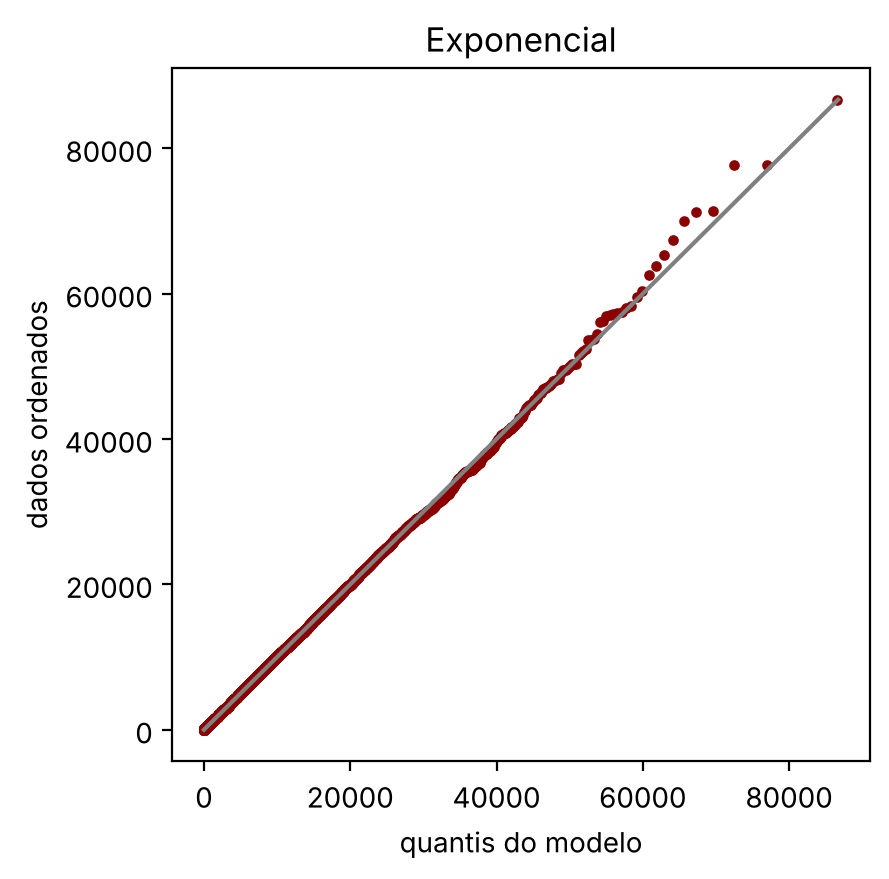

In [11]:
def grafico_qq(tempos, modelo, titulo=""):
    dados = np.sort(tempos)
    n = len(dados)
    posicoes = (np.arange(1, n + 1) - 0.5) / n       # 0.5/n, 1.5/n, ...
    teoricos = modelo.ppf(posicoes)                  # quantis do modelo
    plt.scatter(teoricos, dados, s=8, color="darkred")
    lim = [0, max(teoricos.max(), dados.max())]
    plt.plot(lim, lim, color="gray")
    plt.xlabel("quantis do modelo"); plt.ylabel("dados ordenados"); plt.title(titulo)

plt.figure(figsize=(4.5, 4.5))
grafico_qq(t, modelo, "Exponencial")
plt.show()

### Fiabilidade empírica e fiabilidade do modelo

Para quem trabalha em fiabilidade, este é o gráfico mais direto: a proporção de componentes que ainda funcionam em cada instante (dados) contra a curva $R(t)$ do modelo.

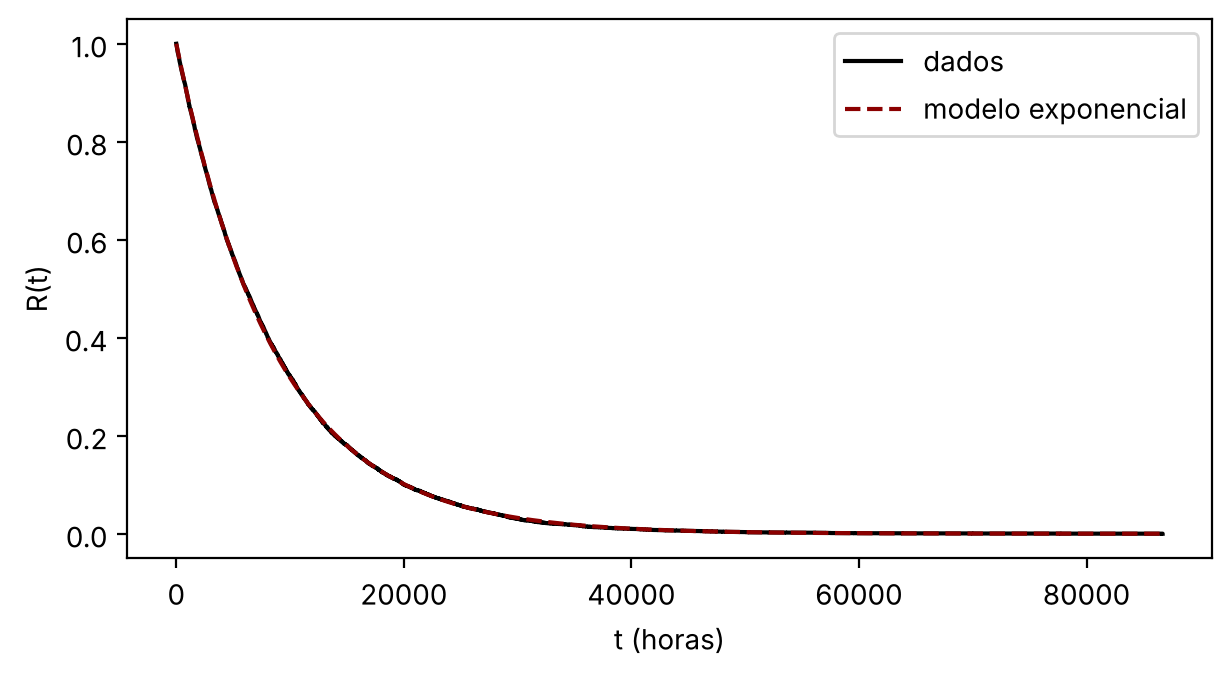

In [12]:
dados = np.sort(t)
R_empirica = 1 - np.arange(1, n + 1) / n

plt.figure(figsize=(7, 3.5))
plt.step(dados, R_empirica, where="post", color="black", label="dados")
plt.plot(x, modelo.sf(x), color="darkred", linestyle="--", label="modelo exponencial")
plt.xlabel("t (horas)"); plt.ylabel("R(t)"); plt.legend()
plt.show()

## 6. Comparar as quatro distribuições do documento base

Para testar outra distribuição só é preciso (1) estimar os seus parâmetros e (2) criar o modelo correspondente. O teste é o mesmo.

| Distribuição | Como se estimam os parâmetros | Modelo em `scipy.stats` | m |
|---|---|---|---|
| Exponencial | MTBF = média dos tempos | `stats.expon(scale=mtbf)` | 1 |
| Normal | média e desvio padrão dos tempos | `stats.norm(media, desvio)` | 2 |
| Lognormal | média e desvio padrão **dos logaritmos** dos tempos | `stats.lognorm(s=sigma, scale=np.exp(mu))` | 2 |
| Weibull (2 parâmetros) | máxima verosimilhança: `stats.weibull_min.fit(t, floc=0)` | `stats.weibull_min(beta, scale=eta)` | 2 |

In [13]:
def ajustar_modelos(tempos):
    # Estima os parâmetros das quatro distribuições e devolve {nome: (modelo, m)}
    log_t = np.log(tempos)
    beta, _, eta = stats.weibull_min.fit(tempos, floc=0)       # floc=0: sem parâmetro de localização
    return {
        "Exponencial": (stats.expon(scale=tempos.mean()), 1),
        "Normal":      (stats.norm(tempos.mean(), tempos.std(ddof=1)), 2),
        "Lognormal":   (stats.lognorm(s=log_t.std(ddof=1), scale=np.exp(log_t.mean())), 2),
        "Weibull":     (stats.weibull_min(beta, scale=eta), 2),
    }

def comparar(tempos):
    linhas = []
    for nome, (mod, m) in ajustar_modelos(tempos).items():
        ET, gl, p_qui2 = teste_qui2(tempos, mod, m, mostrar=False)
        ks = stats.kstest(tempos, mod.cdf)
        linhas.append([nome, ET, gl, p_qui2, ks.statistic, ks.pvalue])
    return pd.DataFrame(linhas, columns=["distribuição", "ET (qui2)", "gl", "valor-p (qui2)",
                                         "D (KS)", "valor-p (KS)"]).round(4)

comparar(t)

,distribuição,ET (qui2),gl,valor-p (qui2),D (KS),valor-p (KS)
0,Exponencial,5.7323,12,0.9290,0.0061,0.8532
1,Normal,5458.6469,11,0.0000,0.1582,0.0000
2,Lognormal,992.7926,11,0.0000,0.0743,0.0000
3,Weibull,6.6005,11,0.8305,0.0068,0.7343


**Como ler a tabela.** A normal e a lognormal são claramente rejeitadas (valor-p praticamente nulo). A exponencial e a Weibull não são rejeitadas.

Porque é que a Weibull também passa? Veja os parâmetros estimados:

In [14]:
beta, _, eta = stats.weibull_min.fit(t, floc=0)
print(f"Weibull: beta = {beta:.3f}, eta = {eta:.1f} horas")
print(f"Exponencial: MTBF = {mtbf:.1f} horas")

Weibull: beta = 0.996, eta = 8725.2 horas
Exponencial: MTBF = 8738.1 horas


O parâmetro de forma deu praticamente 1, e uma Weibull com $\beta = 1$ **é** uma exponencial (com MTBF $= \eta$). Os dois modelos dizem o mesmo. Entre dois modelos equivalentes, escolhe-se o mais simples: a exponencial.

Os gráficos QQ mostram a mesma coisa de forma visual:

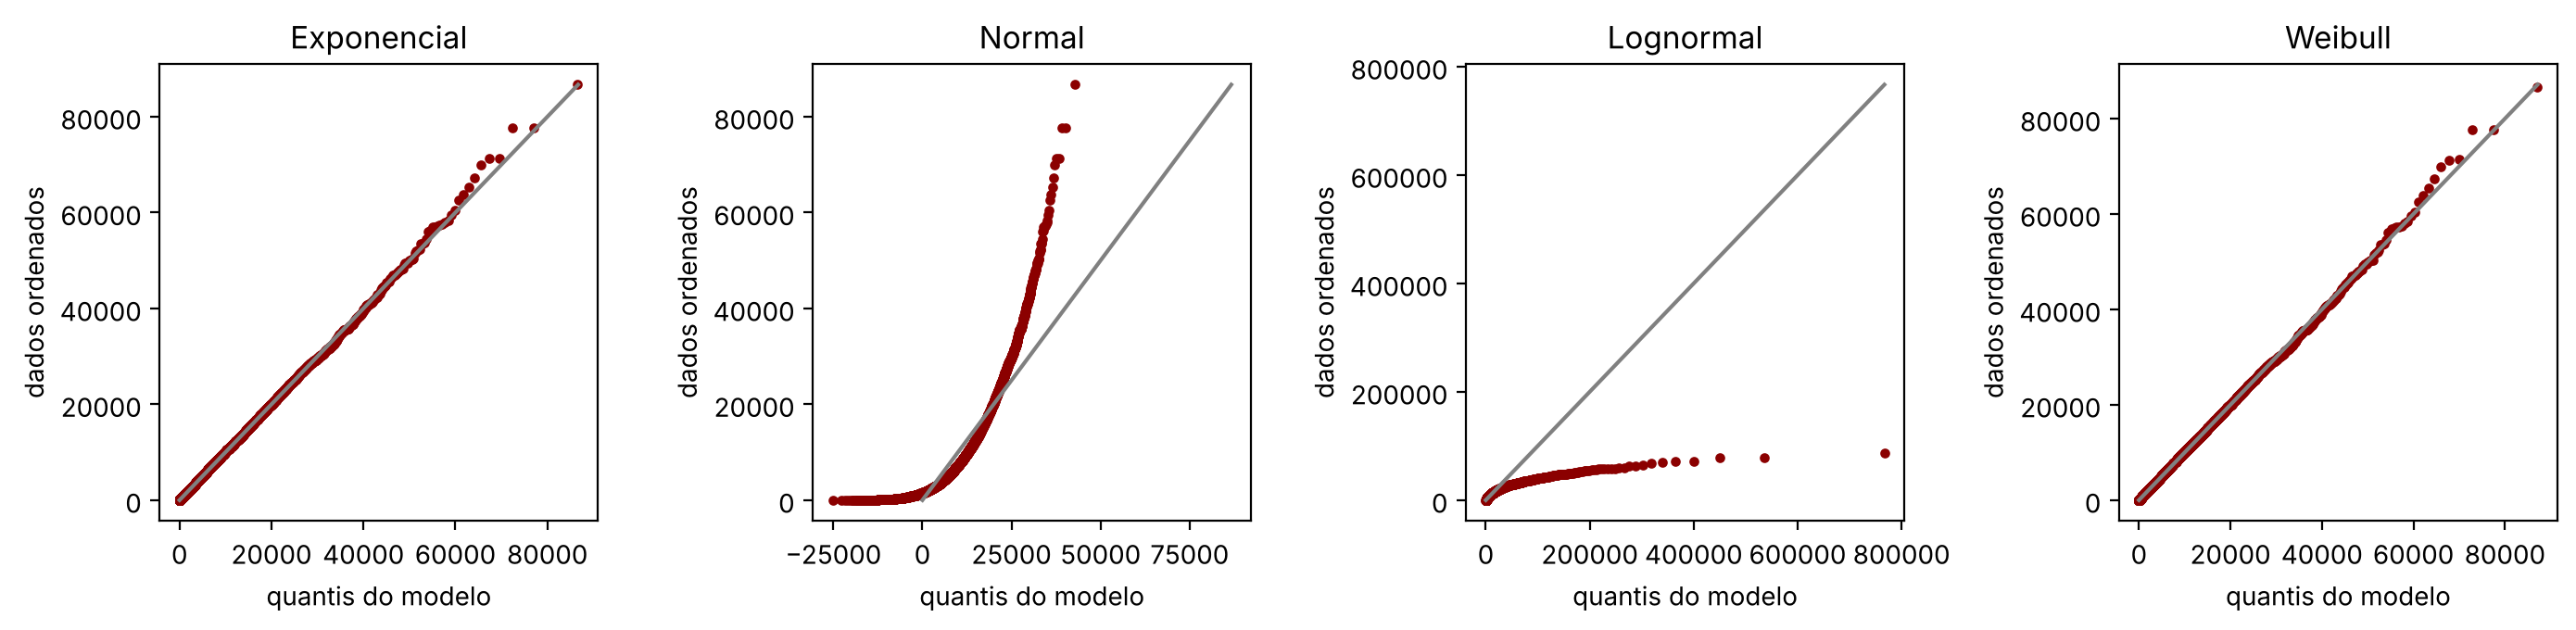

In [15]:
modelos = ajustar_modelos(t)
plt.figure(figsize=(14, 3.5))
for i, (nome, (mod, m)) in enumerate(modelos.items(), 1):
    plt.subplot(1, 4, i)
    grafico_qq(t, mod, nome)
plt.tight_layout(); plt.show()

## 7. O que muda quando há poucos dados

Os dados da aula têm cerca de 10 000 tempos. Os dados do trabalho têm 50 por componente. Para ver o efeito, tiramos ao acaso 50 tempos dos dados da aula e repetimos a comparação.

In [16]:
amostra = pd.Series(t).sample(50, random_state=2026).to_numpy()
comparar(amostra)

,distribuição,ET (qui2),gl,valor-p (qui2),D (KS),valor-p (KS)
0,Exponencial,0.88,4,0.9274,0.0720,0.9411
1,Normal,36.64,3,0.0000,0.1843,0.0586
2,Lognormal,0.40,3,0.9402,0.0709,0.9476
3,Weibull,1.36,3,0.7149,0.0658,0.9721


Com 50 tempos, a lognormal, que antes era rejeitada sem margem para dúvida, **já não é rejeitada**. Os dados são os mesmos; o que mudou foi a quantidade de informação.

Três conclusões para o trabalho:

1. Com amostras pequenas, é frequente **várias distribuições passarem** no teste. "Não rejeitar" não quer dizer que o modelo está certo.
2. Para escolher entre as que passam, juntam-se vários elementos: valores-p, gráficos QQ, simplicidade do modelo e o que se sabe sobre o componente (desgasta-se? tem falhas de arranque?).
3. Vale a pena verificar se a escolha faz diferença no que interessa: calcule $R(t)$ para o tempo de missão com cada modelo candidato e compare.

Experimente mudar `random_state` para outro número e veja como os resultados variam de amostra para amostra.

In [17]:
# Fiabilidade às 2000 horas segundo cada modelo ajustado à amostra de 50 tempos
for nome, (mod, m) in ajustar_modelos(amostra).items():
    print(f"{nome:12s} R(2000) = {mod.sf(2000):.3f}")
print(f"{'Dados (50)':12s} R(2000) = {(amostra > 2000).mean():.3f}")

Exponencial  R(2000) = 0.789
Normal       R(2000) = 0.774
Lognormal    R(2000) = 0.820
Weibull      R(2000) = 0.811
Dados (50)   R(2000) = 0.820


## 8. A sua vez

Aplique o que viu aos dados da instalação. A célula abaixo lê a folha `ensaios_vida` e escolhe um componente. O resto fica por sua conta.

Pistas:

- Comece por um histograma e pela tabela de `comparar(...)`.
- Olhe para os gráficos QQ das distribuições que não foram rejeitadas.
- Estime os parâmetros da Weibull e interprete o valor de $\beta$.
- Repita para os outros componentes. Não se esqueça de que cada um pode seguir uma distribuição diferente.

In [18]:
DADOS = "dados_fiabilidade.xlsx"
URL_DADOS = "https://raw.githubusercontent.com/nlavadodatasci/atd-megaf-fiabilidade/main/dados/" + DADOS

if not os.path.exists(DADOS):
    try:
        urllib.request.urlretrieve(URL_DADOS, DADOS)
    except Exception:
        from google.colab import files
        print("Escolha no seu computador o ficheiro", DADOS)
        carregados = files.upload()
        if DADOS not in carregados:               # veio com outro nome: renomeia
            os.rename(list(carregados)[0], DADOS)

ensaios = pd.read_excel(DADOS, sheet_name="ensaios_vida")
print(list(ensaios["componente"].unique()))

componente = "Interruptor"                      # troque pelo componente que quer estudar
tc = ensaios[ensaios["componente"] == componente]["tempo_ate_falha_h"].to_numpy()
print(componente, "- número de tempos:", len(tc))

# A partir daqui é consigo. Por exemplo:
# comparar(tc)

['Interruptor', 'Transformador', 'QGBT', 'Gerador', 'Controlador']
Interruptor - número de tempos: 50
